# Analysis 5: Do title features affect how long a video trends?

**Business question.** Creators are told to use numbers, questions, capital letters and strong emotion in titles. Among trending videos, do titles with these features stay on the list longer, once we account for who made the video and what it is about?

**Features** (from `streampulse/titles.py`):

| Feature | Rule |
|---|---|
| has_number | any digit |
| has_question | contains `?` |
| has_exclamation | contains `!` |
| has_caps_word | a word of 3 or more capital letters (also catches acronyms like NBA) |
| has_emoji | any emoji |
| has_shorts_tag | `#shorts` or `#short`, which marks the YouTube Shorts format |
| has_other_hashtag | any other hashtag |
| has_pipe | a `\|` separator, common in Indian titles |
| title_words | number of words |
| sentiment | VADER positive, neutral or negative |

VADER only understands English, so titles written mostly in another script are marked "not scored" instead of being counted as neutral. That affects 24.8% of Indian titles and about 1.5% elsewhere. Romanised Hindi ("Hinglish") is in Latin script but mostly unknown to VADER, so Indian sentiment scores are weaker evidence.

**Outcome and method.** Days on the trending list for completed runs. Linear regression per country with HC1 robust standard errors, controlling for category, trending year, India's data period, and the channel's typical run length (its average days on the list for its other trending videos).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from streampulse.analysis import load_title_runs
from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, apply_chart_style
from streampulse.database import connect
from streampulse.titles import TITLE_FEATURES, add_title_features

BINARY_FEATURES = [feature for feature in TITLE_FEATURES if feature.startswith("has_")]

apply_chart_style()
with connect() as connection:
    title_runs = add_title_features(load_title_runs(connection))
title_runs[BINARY_FEATURES] = title_runs[BINARY_FEATURES].astype(int)

print(f"{len(title_runs):,} completed runs")
title_runs.groupby("country")["days_trending"].describe().loc[COUNTRIES].round(2)

172,436 completed runs


,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
IN,78487.0,3.15,1.67,1.0,2.0,3.0,4.0,11.0
US,46742.0,5.63,1.89,1.0,5.0,6.0,6.0,37.0
GB,47207.0,5.56,1.61,1.0,5.0,6.0,6.0,17.0


## 1. How common each feature is

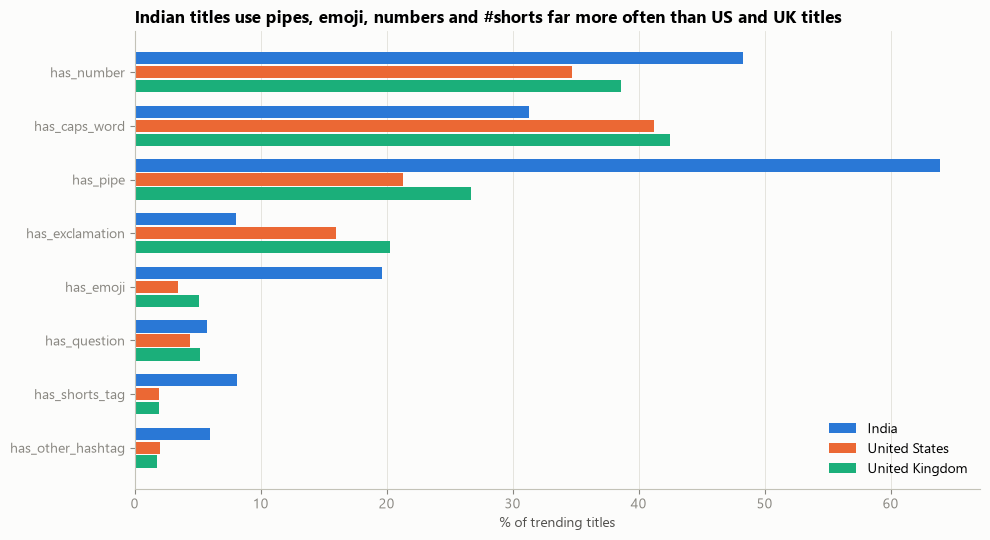

country,IN,US,GB
has_number,48.3,34.7,38.6
has_question,5.7,4.4,5.2
has_exclamation,8.0,16.0,20.3
has_caps_word,31.3,41.2,42.5
has_emoji,19.6,3.4,5.1
has_shorts_tag,8.1,1.9,1.9
has_other_hashtag,6.0,2.0,1.8
has_pipe,63.9,21.3,26.7
sentiment: negative,11.6,21.5,21.4
sentiment: neutral,39.7,53.4,50.3


In [2]:
feature_share = (100 * title_runs.groupby("country")[BINARY_FEATURES].mean()).T[COUNTRIES].round(1)
sentiment_share = (100 * pd.crosstab(title_runs["sentiment_label"], title_runs["country"], normalize="columns"))[COUNTRIES].round(1)

fig, ax = plt.subplots(figsize=(10, 5.5))
feature_order = feature_share.mean(axis=1).sort_values().index
bar_height = 0.26
for offset, country in zip([bar_height, 0, -bar_height], COUNTRIES):
    ax.barh(np.arange(len(feature_order)) + offset, feature_share.loc[feature_order, country], height=bar_height - 0.03,
            color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
ax.set_yticks(range(len(feature_order)), feature_order)
ax.set_xlabel("% of trending titles")
ax.grid(axis="y", visible=False)
ax.set_title("Indian titles use pipes, emoji, numbers and #shorts far more often than US and UK titles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

pd.concat([feature_share, sentiment_share.rename(index=lambda label: f"sentiment: {label}")])

## 2. Raw differences

Average days on the list with and without each feature, before any controls. These mix the effect of the title with everything else that differs between the videos that use a feature and those that do not.

In [3]:
raw_rows = []
for country in COUNTRIES:
    country_runs = title_runs[title_runs["country"] == country]
    for feature in BINARY_FEATURES:
        with_feature = country_runs.loc[country_runs[feature] == 1, "days_trending"].mean()
        without_feature = country_runs.loc[country_runs[feature] == 0, "days_trending"].mean()
        raw_rows.append({"country": country, "feature": feature, "raw_difference_days": with_feature - without_feature})
raw_differences = pd.DataFrame(raw_rows).pivot(index="feature", columns="country", values="raw_difference_days")[COUNTRIES]
raw_differences.round(2)

country,IN,US,GB
feature,,,
has_caps_word,0.02,-0.22,-0.11
has_emoji,-0.03,-0.44,-0.43
has_exclamation,-0.31,-0.06,-0.27
has_number,-0.41,-0.19,-0.27
has_other_hashtag,-0.06,-0.40,0.02
has_pipe,0.14,-0.31,-0.38
has_question,-0.38,-0.07,-0.02
has_shorts_tag,0.21,-0.88,-0.43


## 3. Effects after controls

Coefficients are extra days on the list for titles with the feature, holding the other features and the controls fixed. Neutral sentiment is the reference for the sentiment terms. Only channels with at least two completed runs in the country are included, since the others have no typical run length.

In [4]:
feature_terms = " + ".join(TITLE_FEATURES) + " + C(sentiment_label, Treatment('neutral'))"
control_terms = "C(category) + C(trending_year) + channel_typical_days"

fitted_models = {}
effect_rows = []
for country in COUNTRIES:
    country_runs = title_runs[(title_runs["country"] == country)].dropna(subset=["channel_typical_days"])
    country_controls = control_terms + (" + C(country_period)" if country == "IN" else "")
    fitted_model = smf.ols(f"days_trending ~ {feature_terms} + {country_controls}", data=country_runs).fit(cov_type="HC1")
    fitted_models[country] = fitted_model
    conf_int = fitted_model.conf_int()
    for term in fitted_model.params.index:
        if term in TITLE_FEATURES or "sentiment_label" in term:
            effect_rows.append({
                "country": country,
                "term": term.replace("C(sentiment_label, Treatment('neutral'))[T.", "sentiment: ").rstrip("]"),
                "days": fitted_model.params[term],
                "ci_low": conf_int.loc[term, 0],
                "ci_high": conf_int.loc[term, 1],
                "p_value": fitted_model.pvalues[term],
                "mean_days": country_runs["days_trending"].mean(),
            })
    print(f"{country}: {len(country_runs):,} runs, R-squared = {fitted_model.rsquared:.3f}")

title_effects = pd.DataFrame(effect_rows)
title_effects["pct_of_mean_days"] = 100 * title_effects["days"] / title_effects["mean_days"]
title_effects = title_effects[~title_effects["term"].str.contains("not scored")]

IN: 77,573 runs, R-squared = 0.253


US: 43,118 runs, R-squared = 0.143


GB: 43,958 runs, R-squared = 0.221


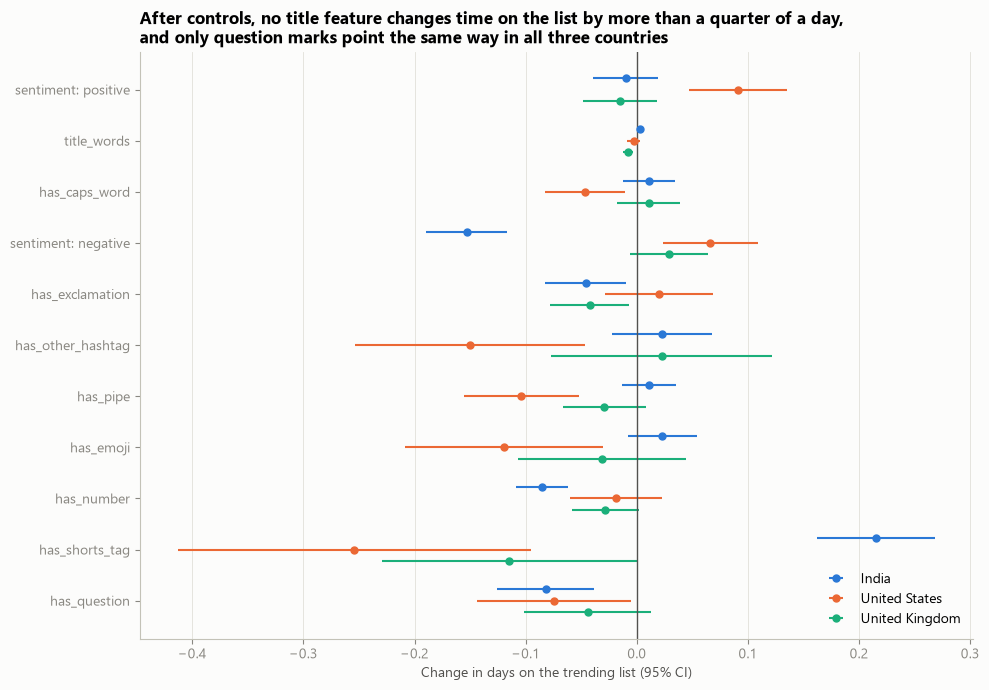

country,IN,US,GB
term,,,
sentiment: positive,-0.010,0.091,-0.015
title_words,0.003,-0.003,-0.008
has_caps_word,0.011,-0.047,0.011
sentiment: negative,-0.153,0.066,0.029
has_exclamation,-0.046,0.020,-0.043
has_other_hashtag,0.022,-0.150,0.022
has_pipe,0.011,-0.104,-0.029
has_emoji,0.023,-0.120,-0.031
has_number,-0.085,-0.019,-0.028


In [5]:
term_order = title_effects.groupby("term")["days"].mean().sort_values().index

fig, ax = plt.subplots(figsize=(10, 7))
for offset, country in zip([0.22, 0, -0.22], COUNTRIES):
    rows = title_effects[title_effects["country"] == country].set_index("term").reindex(term_order)
    ax.errorbar(rows["days"], np.arange(len(term_order)) + offset,
                xerr=[rows["days"] - rows["ci_low"], rows["ci_high"] - rows["days"]],
                fmt="o", markersize=5, color=COUNTRY_COLORS[country], elinewidth=1.5, label=COUNTRY_NAMES[country])
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(range(len(term_order)), term_order)
ax.set_xlabel("Change in days on the trending list (95% CI)")
ax.grid(axis="y", visible=False)
ax.set_title("After controls, no title feature changes time on the list by more than a quarter of a day,\n"
             "and only question marks point the same way in all three countries")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

title_effects.pivot(index="term", columns="country", values="days")[COUNTRIES].loc[term_order[::-1]].round(3)

## 4. How much titles explain overall

An F-test compares each country's full model with the same model minus every title term. The partial R-squared is the share of the variance left after the controls that the title terms explain. The channel's typical run length is shown for comparison.

In [6]:
block_rows = []
for country in COUNTRIES:
    country_runs = title_runs[(title_runs["country"] == country)].dropna(subset=["channel_typical_days"])
    country_controls = control_terms + (" + C(country_period)" if country == "IN" else "")
    full_model = smf.ols(f"days_trending ~ {feature_terms} + {country_controls}", data=country_runs).fit()
    without_titles = smf.ols(f"days_trending ~ {country_controls}", data=country_runs).fit()
    without_channel = smf.ols(
        f"days_trending ~ {feature_terms} + {country_controls.replace(' + channel_typical_days', '')}", data=country_runs
    ).fit()
    f_statistic, p_value, _ = full_model.compare_f_test(without_titles)
    block_rows.append({
        "country": country,
        "title_terms_partial_r2": (without_titles.ssr - full_model.ssr) / without_titles.ssr,
        "title_terms_f": f_statistic,
        "title_terms_p": p_value,
        "channel_typical_days_partial_r2": (without_channel.ssr - full_model.ssr) / without_channel.ssr,
        "titles_only_r2": smf.ols(f"days_trending ~ {feature_terms}", data=country_runs).fit().rsquared,
    })
pd.DataFrame(block_rows).set_index("country").style.format({
    "title_terms_partial_r2": "{:.4f}", "title_terms_f": "{:.1f}", "title_terms_p": "{:.1g}",
    "channel_typical_days_partial_r2": "{:.3f}", "titles_only_r2": "{:.3f}",
})

,title_terms_partial_r2,title_terms_f,title_terms_p,channel_typical_days_partial_r2,titles_only_r2
country,,,,,
IN,0.0039,25.1,3e-57,0.180,0.037
US,0.0021,7.6,3e-14,0.069,0.015
GB,0.0013,4.8,6e-08,0.097,0.031


## Finding

**Title style has almost no effect on how long a trending video stays on the list. The channel matters far more.**

- **Titles alone explain little:** 1.5% (US) to 3.7% (India) of the variation in days on the list. After the controls, all title terms together explain 0.13% (UK) to 0.39% (India) of what is left. The channel's typical run length explains 7% to 18%. The title terms are jointly significant (p below 1e-7 in every country), but small.
- **Raw gaps shrink once the channel is accounted for.** In the US, `#shorts` titles run 0.88 days shorter before controls and 0.25 days after; emoji titles 0.44 days shorter before and 0.12 after.
- **No adjusted effect is larger than a quarter of a day.** The largest are `#shorts`: 0.25 days shorter in the US (4.5% of the average run) but 0.22 days longer in India (6.8%). The Shorts format behaves differently by country.
- **Only question marks agree across countries**: 0.04 to 0.08 days shorter, significant in India and the US but not the UK.
- **Sentiment shows no consistent pattern.** In the US, positive (+0.09 days) and negative (+0.07) titles both run slightly longer than neutral ones. In India negative titles run 0.15 days shorter (about 5%). In the UK there is no clear effect.
- **Multiple testing:** 33 coefficients were tested (11 terms in 3 countries), so one or two would pass p < 0.05 by chance. Effects seen in only one country should be treated as weak evidence.

**Business answer.** Common title advice (numbers, questions, capitals, emotion) is not what keeps a video trending. The title optimizer in Phase 4 should be framed as improving clarity and click appeal, not as a way to extend time on the list.

**Limitations**

- Only trending videos are included. Titles may matter more for whether a video trends at all, which this data cannot test.
- VADER does not cover 24.8% of Indian titles (non-Latin script) and understands little Hinglish.
- The features are simple text rules. "Caps word" also counts acronyms such as NBA or BTS.
- The channel control comes from the channel's other trending runs, so single-video channels are left out.